<a href="https://colab.research.google.com/github/swethaeng2007-creator/ML-23CSE301/blob/main/Experiment-01-Linear-Regression/Experiment1_Height_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [6]:
data = {
    "Weight":[79,69,73,95,82,55,69,71,64,69],
    "Height":[1.80,1.68,1.82,1.70,1.87,1.55,1.50,1.78,1.67,1.64],
    "Age":[35,39,25,60,27,18,89,42,16,52],
    "Gender":["Male","Male","Male","Male","Male",
              "Female","Female","Female","Female","Female"]
}

df = pd.DataFrame(data)

df

,Weight,Height,Age,Gender
0,79,1.80,35,Male
1,69,1.68,39,Male
2,73,1.82,25,Male
3,95,1.70,60,Male
4,82,1.87,27,Male
5,55,1.55,18,Female
6,69,1.50,89,Female
7,71,1.78,42,Female
8,64,1.67,16,Female
9,69,1.64,52,Female


In [7]:
print(df.head())

print("\nShape:", df.shape)

print("\nInformation:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe())

   Weight  Height  Age Gender
0      79    1.80   35   Male
1      69    1.68   39   Male
2      73    1.82   25   Male
3      95    1.70   60   Male
4      82    1.87   27   Male

Shape: (10, 4)

Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Weight  10 non-null     int64  
 1   Height  10 non-null     float64
 2   Age     10 non-null     int64  
 3   Gender  10 non-null     object 
dtypes: float64(1), int64(2), object(1)
memory usage: 452.0+ bytes
None

Statistical Summary:
          Weight     Height        Age
count  10.000000  10.000000  10.000000
mean   72.600000   1.701000  40.300000
std    10.834103   0.118832  22.181323
min    55.000000   1.500000  16.000000
25%    69.000000   1.647500  25.500000
50%    70.000000   1.690000  37.000000
75%    77.500000   1.795000  49.500000
max    95.000000   1.870000  89.000000


In [8]:
print(df.isnull().sum())

Weight    0
Height    0
Age       0
Gender    0
dtype: int64


In [9]:
X = df[['Weight']]
y = df['Height']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [11]:
model = LinearRegression()

model.fit(X_train, y_train)


LinearRegression()

In [12]:
print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])

Intercept: 1.2676416458525044
Slope: 0.0059340081503878


In [13]:
y_pred = model.predict(X_test)

print("Actual Heights:")
print(y_test.values)

print("\nPredicted Heights:")
print(y_pred)

Actual Heights:
[1.67 1.68]

Predicted Heights:
[1.64741817 1.67708821]


In [14]:
print("MAE :", mean_absolute_error(y_test, y_pred))
print("MSE :", mean_squared_error(y_test, y_pred))
print("RMSE :", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score :", r2_score(y_test, y_pred))

MAE : 0.01274681214670681
MSE : 0.0002592088456991676
RMSE : 0.016099964152108154
R2 Score : -9.368353827966686


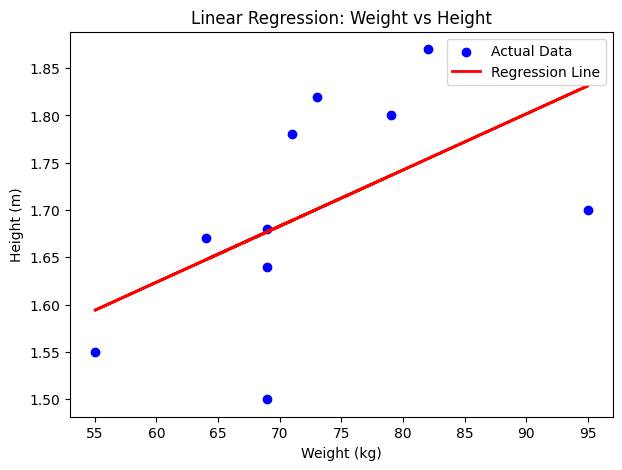

In [15]:
plt.figure(figsize=(7,5))

plt.scatter(X, y, color='blue', label='Actual Data')

plt.plot(X, model.predict(X), color='red', linewidth=2, label='Regression Line')

plt.xlabel("Weight (kg)")
plt.ylabel("Height (m)")
plt.title("Linear Regression: Weight vs Height")

plt.legend()

plt.show()

In [16]:
new_weight = pd.DataFrame({'Weight':[75]})

predicted_height = model.predict(new_weight)

print("Predicted Height for 75 kg person =", round(predicted_height[0],2), "meters")

Predicted Height for 75 kg person = 1.71 meters
